# Extension: debiasing RTE's forecast

Verdict: Removing RTE's recent bias at each hour is the best result we got: 830 MW on the folds and 819 MW on the test, against 860 and 910 MW for the LightGBM residual and 1,439 MW for RTE raw (-43.1 %).

Setup: Cutoff D 12:00, forecast the 24 h of D+1, test 1 Jul 2025 to 30 Jun 2026.

This is not a learnt model, just a correction rule applied to RTE's forecast. The idea comes from the analysis of
RTE's error in 00_eda (a bias of about -1.1 GW since 2023). We show it here, at the end, as an extension.

## 1. Setup

Same constants as 05: the 4 quarterly walk-forward folds (1 July 2024 to 30 June 2025) for every choice, the
test year only to report, and the LightGBM residual with the same parameters, trained since 2019.

In [1]:
import sys
sys.path.insert(0, "../src")

from datetime import date, timedelta

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from watt_forecast.data_preprocessing import load_dataset, save_predictions
from watt_forecast.features import make_features, feature_cols
from watt_forecast.metrics import compute_metrics, evaluate, scorecard
from watt_forecast.models.baseline import debias_rte, debias_rte_hourly
from watt_forecast.models.gbm import fit_residual, predict_residual, walk_forward_predictions

TRAIN_END = date(2025, 6, 30)
TEST_START, TEST_END = date(2025, 7, 1), date(2026, 6, 30)
FOLDS = [
    (date(2024, 7, 1), date(2024, 9, 30)),
    (date(2024, 10, 1), date(2024, 12, 31)),
    (date(2025, 1, 1), date(2025, 3, 31)),
    (date(2025, 4, 1), date(2025, 6, 30)),
]
FOLD_NAMES = ["Q3_2024", "Q4_2024", "Q1_2025", "Q2_2025"]
VALID_START, VALID_END = FOLDS[0][0], FOLDS[-1][1]

PARAMS = dict(num_leaves=31, learning_rate=0.05, n_estimators=500)  # chosen in 04_lightgbm
RESIDUAL_START = date(2019, 1, 1)  # chosen in 05_final_model

pl.Config.set_tbl_rows(30)
plt.rcParams["figure.figsize"] = (12, 4)

In [2]:
df = load_dataset()
features = make_features(df, "persistence", with_rte=True)
assert features.height == df.height and (features["datetime_utc"] == df["datetime_utc"]).all(), "same rows"

## 2. The rule

- Flat: RTE minus its mean error (RTE - actual) over the 28 days T-29 to T-2.
- By hour: RTE minus its mean error at the same local hour over T-29 to T-2.

T-2 is the last complete day at the cutoff, so both rules only use known data. The test below checks it.

In [3]:
df = debias_rte_hourly(debias_rte(df))

rules = {"RTE debiased (flat)": "rte_debiased_mw", "RTE debiased by hour": "rte_debiased_hourly_mw"}
df.select(rules.values()).null_count()

rte_debiased_mw,rte_debiased_hourly_mw
u32,u32
702,367


In [4]:
# Cutoff test: changing the load of T-1 must not change the forecast of T, changing T-2 must
T = date(2025, 1, 15)


def forecast_of_T(table, col):
    return debias_rte_hourly(debias_rte(table)).filter(pl.col("date") == T)[col]


def bump(day):
    return df.with_columns(pl.when(pl.col("date") == day).then(pl.col("target") + 10_000).otherwise(pl.col("target")))


for name, col in rules.items():
    ref = forecast_of_T(df, col)
    assert (forecast_of_T(bump(T - timedelta(days=1)), col) == ref).all(), f"{name}: T-1 must not be used"
    assert (forecast_of_T(bump(T - timedelta(days=2)), col) != ref).all(), f"{name}: T-2 must be used"
print("cutoff test passed for both rules")

cutoff test passed for both rules


## 3. Validation (folds only)

The rules have nothing to train, so on each fold they are simply applied. The LightGBM residual is recomputed
with the same walk-forward as in 05. Cold evening peaks are those of the validation period.

In [5]:
valid = df.filter(pl.col("date").is_between(VALID_START, VALID_END))
preds = walk_forward_predictions(
    features.filter(pl.col("date") >= RESIDUAL_START), FOLDS, PARAMS, fit=fit_residual, predict_fn=predict_residual
)
valid = valid.join(preds.select("datetime_utc", pl.col("pred").alias("lgbm_residual")), on="datetime_utc", how="left", maintain_order="left")
assert valid.height == (VALID_END - VALID_START + timedelta(days=1)).days * 24, "one row per validation hour"

forecasts = {"RTE raw": "rte_forecast_j1_mw", **rules, "LightGBM residual": "lgbm_residual"}


def fold_mae(table, col):
    return [compute_metrics(table.filter(pl.col("date").is_between(a, b)), col)["MAE"] for a, b in FOLDS]


def cold_peak_mae(table, col):
    return evaluate(table, col).filter(pl.col("scope") == "evening_peak_18-20h_cold_days")["MAE"].item()


cv_table = pl.DataFrame(
    [{"model": name, **dict(zip(FOLD_NAMES, fold_mae(valid, col))), "mean": np.mean(fold_mae(valid, col)),
      "cold_evening_peaks": cold_peak_mae(valid, col)}
     for name, col in forecasts.items()]
).sort("mean")
cv_table.with_columns(pl.exclude("model").round(0))

model,Q3_2024,Q4_2024,Q1_2025,Q2_2025,mean,cold_evening_peaks
str,f64,f64,f64,f64,f64,f64
"""RTE debiased by hour""",616.0,905.0,1039.0,760.0,830.0,1245.0
"""LightGBM residual""",653.0,968.0,999.0,819.0,860.0,1478.0
"""RTE debiased (flat)""",870.0,1089.0,1270.0,980.0,1052.0,1566.0
"""RTE raw""",1140.0,1381.0,1369.0,1560.0,1362.0,1822.0


What we see. The hourly rule has the best mean on the folds (830 MW, against 860 for the LightGBM residual) and it wins on 3 folds out of 4, all but Q1 2025 (1,039 vs 999 MW). It is also clearly better on the cold evening peaks of the validation (1,245 vs 1,478 MW). The flat rule helps (1,052 vs 1,362 MW for RTE raw) but much less: RTE's bias is not the same at every hour. The choice is made here, before the test.

## 4. Results vs benchmark (test)

Same 4 forecasts on the test year, RTE raw as reference. The LightGBM residual is trained up to 30 June 2025 as
in 05.

In [6]:
train = features.filter(pl.col("date").is_between(RESIDUAL_START, TRAIN_END)).drop_nulls("lag_336")
test_rows = features.filter(pl.col("date").is_between(TEST_START, TEST_END))
assert train["date"].max() < test_rows["date"].min(), "training rows must come before the test"
cols = feature_cols(features)
model = fit_residual(train.select(cols), train["target"], PARAMS)

test = df.filter(pl.col("date").is_between(TEST_START, TEST_END)).with_columns(
    pl.Series("lgbm_residual", predict_residual(model, test_rows.select(cols))).fill_nan(None)
)
assert test.height == 365 * 24, "the test period should have 8,760 hours"

# Test forecasts of this notebook (not read by 06_comparison)
save_predictions(test, rules, "extension_rte_debiased")

In [7]:
scorecard(test, forecasts)

forecast,global,evening_peak_18-20h,evening_peak_cold_days,vs_reference_(%)
str,f64,f64,f64,f64
"""RTE raw""",1439.0,1348.0,2307.0,0.0
"""RTE debiased (flat)""",1112.0,1186.0,1750.0,-22.7
"""RTE debiased by hour""",819.0,943.0,1528.0,-43.1
"""LightGBM residual""",910.0,987.0,1906.0,-36.8


What we see. Same order on the test. The hourly rule gets 819 MW, 43.1 % below RTE raw, and the LightGBM residual 910 MW. The gap is even bigger on the cold evening peaks (1,528 vs 1,906 MW). The flat rule stays far behind (1,112 MW).

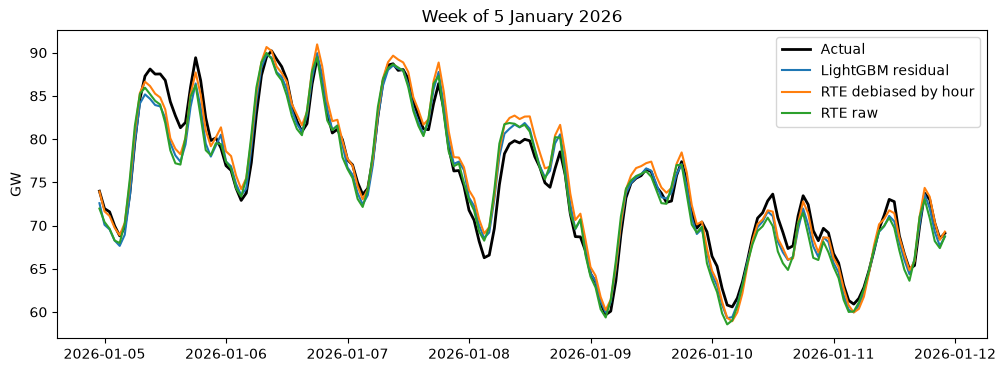

MAE over the week (MW): {'RTE raw': 1506, 'RTE debiased (flat)': 1486, 'RTE debiased by hour': 1319, 'LightGBM residual': 1211}
null hours on the test: (1, 1)


In [8]:
week = test.filter(pl.col("date").is_between(date(2026, 1, 5), date(2026, 1, 11)))

plt.plot(week["datetime_local"], week["target"] / 1000, color="k", lw=2, label="Actual")
plt.plot(week["datetime_local"], week["lgbm_residual"] / 1000, label="LightGBM residual")
plt.plot(week["datetime_local"], week["rte_debiased_hourly_mw"] / 1000, label="RTE debiased by hour")
plt.plot(week["datetime_local"], week["rte_forecast_j1_mw"] / 1000, label="RTE raw")
plt.title("Week of 5 January 2026")
plt.ylabel("GW")
plt.legend()
plt.show()

print("MAE over the week (MW):", {name: round(compute_metrics(week, col)["MAE"]) for name, col in forecasts.items()})
print("null hours on the test:", test.select(rules.values()).null_count().row(0))

On the cold week the LightGBM residual is a bit better (1,211 vs 1,319 MW). The hourly rule follows RTE's shape and misses the same days: the morning of 5 January and 8 January, where it is even a bit higher than RTE. One hour per rule is missing on the test (the repeated October hour, as for RTE).

## 5. Conclusion

- The hourly debiasing is the best result we got, on the folds (830 MW vs 860 for the LightGBM residual) and on the test
  (819 vs 910 MW, and 1,528 vs 1,906 MW on cold evening peaks).
- It is not a learnt model. It removes RTE's usual bias, which is also what the LightGBM residual learns, but
  without any feature.
- Limits: it fails the same days as RTE (see 05, appendix A.6, the worst days), and it follows a sudden change of
  the bias with about a month of delay (28-day window).
- For the recommendation: the simplest and best candidate, to be validated in production alongside the LightGBM
  residual.